# Problema 1 - Regressão Linear para Previsão de Produção de Energia (Usina de Ciclo Combinado)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Carregando o dataset da usina (UCI CCPP)
df = pd.read_csv('ccpp.csv')

## Verificando as primeiras linhas e se existem valores ausentes
print('Formato do dataset:', df.shape)
print('\nValores ausentes por coluna:')
print(df.isna().sum())
df.head()

Formato do dataset: (9568, 5)

Valores ausentes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## Tarefas 1 e 2: Análise de Correlação e Multicolinearidade

Matriz de Correlacao:
        AT       V      AP      RH      PE
AT  1.0000  0.8441 -0.5075 -0.5425 -0.9481
V   0.8441  1.0000 -0.4135 -0.3122 -0.8698
AP -0.5075 -0.4135  1.0000  0.0996  0.5184
RH -0.5425 -0.3122  0.0996  1.0000  0.3898
PE -0.9481 -0.8698  0.5184  0.3898  1.0000


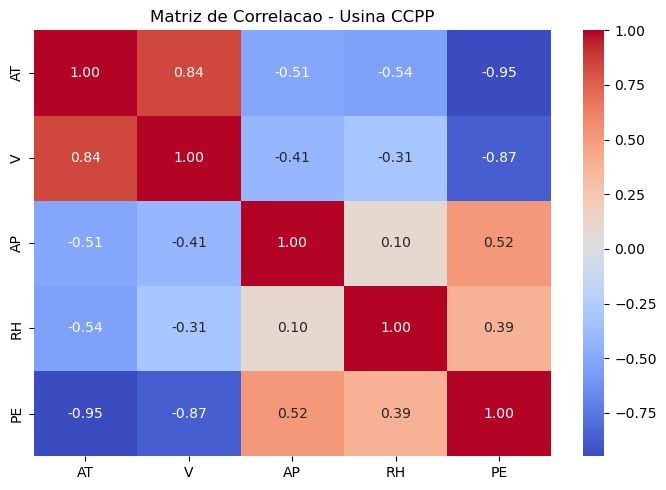

In [2]:
## Calculando a matriz de correlacao entre todas as variaveis
correlacao = df.corr()
print('Matriz de Correlacao:')
print(correlacao.round(4))

## Plotando o mapa de calor para facilitar a visualizacao
plt.figure(figsize=(7, 5))
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlacao - Usina CCPP')
plt.tight_layout()
plt.show()

### Análise das Tarefas 1 e 2

**1. Correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE):**
- **AT (Temperatura Ambiente):** possui correlação de **-0.9481** com PE (correlação negativa muito forte).
- **V (Vácuo de Escape):** possui correlação de **-0.8698** com PE (correlação negativa forte).
- **AP (Pressão Atmosférica):** possui correlação de **0.5184** com PE (correlação positiva moderada).
- **RH (Umidade Relativa):** possui correlação de **0.3898** com PE (correlação positiva fraca a moderada).

Portanto, as variáveis que têm **maior influência** na produção de energia são **AT** e **V**. Quando a temperatura ambiente ou o vácuo de escape aumentam, a potência elétrica gerada pela usina diminui.

**2. Correlação das variáveis independentes entre si (Multicolinearidade):**
- Observa-se uma correlação positiva forte de **0.8441** entre **AT** e **V**.
- Também há correlações negativas moderadas entre **AT e RH (-0.5425)** e entre **AT e AP (-0.5075)**.
- A relação forte entre AT e V indica a presença de **multicolinearidade**, já que ambas carregam informações parcialmente redundantes para o modelo linear.

## Tarefa 3: Pré-processamento, Divisão Treino/Teste e Modelo de Regressão Linear Múltipla

In [3]:
## Separando as variaveis independentes (X) e a variavel dependente alvo (y)
X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

## Dividindo os dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Padronizando as variaveis independentes (Z-score)
## O fit e feito apenas no treino para evitar vazamento de dados (data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Criando e treinando o modelo de Regressao Linear Multipla
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

print('Intercepto (b0):', round(modelo.intercept_, 4))
for nome, coef in zip(X.columns, modelo.coef_):
    print(f'Coeficiente {nome}: {coef:.4f}')

Intercepto (b0): 454.431
Coeficiente AT: -14.7639
Coeficiente V: -2.9496
Coeficiente AP: 0.3698
Coeficiente RH: -2.3122


## Tarefa 4: Avaliação do Desempenho do Modelo

R2 (Coeficiente de Determinacao): 0.9301
RMSE (Raiz do Erro Quadratico Medio): 4.5026 MW
MAE (Erro Medio Absoluto): 3.5959 MW


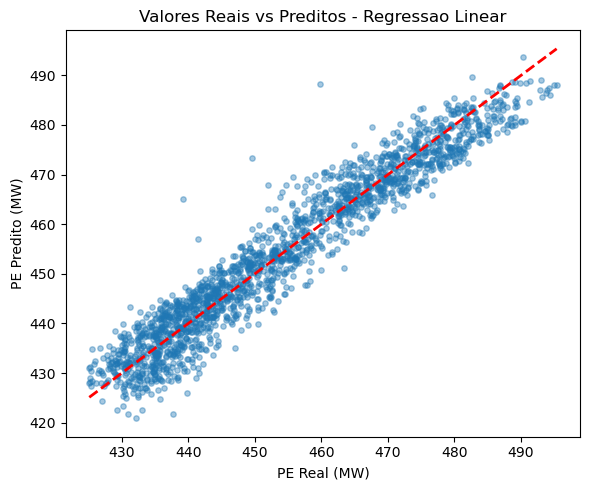

In [4]:
## Fazendo as previsoes no conjunto de teste
y_pred = modelo.predict(X_test_scaled)

## Calculando as metricas R2, RMSE e MAE
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f'R2 (Coeficiente de Determinacao): {r2:.4f}')
print(f'RMSE (Raiz do Erro Quadratico Medio): {rmse:.4f} MW')
print(f'MAE (Erro Medio Absoluto): {mae:.4f} MW')

## Grafico comparando valores reais vs valores preditos
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.4, s=15)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('PE Real (MW)')
plt.ylabel('PE Predito (MW)')
plt.title('Valores Reais vs Preditos - Regressao Linear')
plt.tight_layout()
plt.show()

### Análise da Tarefa 4

**Métricas obtidas no conjunto de teste:**
- **$R^2$:** `0.9301`
- **RMSE:** `4.5026 MW`
- **MAE:** `3.5959 MW`

**O modelo é adequado para prever a produção de energia? Justificativa:**
Sim, o modelo é adequado. O coeficiente de determinação ($R^2 = 0.9301$) mostra que aproximadamente **93% da variação** na potência elétrica gerada pela usina é explicada linearmente pelas quatro variáveis ambientais. Além disso, considerando que a produção de energia varia entre cerca de 420 MW e 495 MW, um erro médio absoluto (MAE) de **3.60 MW** e um RMSE de **4.50 MW** representam um erro percentual abaixo de 1%, indicando boa precisão para auxiliar na estimativa de despacho energético.